# `cluster-barcodes.ipynb`

Clustering FASTQ barcodes using the Levenshtein distance and DBSCAN clustering.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # for heatmaps
import Levenshtein # for distance computation
from sklearn.cluster import DBSCAN # for clustering
from tqdm import trange # for loop progress bar

In [2]:
def readFastq(filename):
    '''
    Read FASTQ file. Outputs two numpy arrays, `sequences` and `qualities`. `sequences` is an array of the nucleotide sequences
    
    Copied from this source: https://hossainlab.github.io/PY4B/notebooks/05-Working%20with%20FASTQ%20Sequence%20Data.html.
    The only change I made was to output numpy arrays at the end, instead of lists.
    '''
    sequences = []
    qualities = []
    with open(filename) as fh:
        while True:
            fh.readline() # skip name line
            seq = fh.readline().rstrip() # read base sequence
            fh.readline() # skip placeholder line
            qual = fh.readline().rstrip() #base quality line
            if len(seq) == 0:
                break
            sequences.append(seq)
            qualities.append(qual)
    return np.array(sequences), np.array(qualities)

In [3]:
# extendedFrags contains trimmed *and* merged files (if I understand correctly)
sequences, qualities = readFastq('./fish16_s6_rep1_out.extendedFrags.fastq')
print(f'The first read sequence is: \'{sequences[0]}\'.')

The first read sequence is: 'AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAGTCGAGAGCGCGCTCGTCGACTATGGAGTCGTCAGCAGTACTACTGACGATGGAGTCGACAGCAGTGTGTGAGTCTATGGAGTCGAGAGCATAGACATCGAGTATGGAGTCGACTACAGTCGCTACGACTATGGAGTCGACAGAGATATCATGCAGTATGGAGTCGACAGCAGTATCTGCTGTCATGGAGTCGACTGCACGACAGTCGACTATGGAGTCGCGAGCGCTATGAGGGGCTATGGGCATGCAATTAAGTCTCAGCCACCGTTAACTGAACATGTCAAAACC'.


## Cluster using unique sequences in the file, not including counts.

In [4]:
# There are repeated sequences, but we just want the unique ones.
unique_seqs, seq_counts = np.unique(sequences, return_counts = True)
n_seqs = len(unique_seqs)

print(f'There are {len(sequences)} sequences in the file. {n_seqs} of them are unique.')

There are 5341 sequences in the file. 489 of them are unique.


In [5]:
# Compute Levenshtein distance between every pair of reads.
distances = np.zeros((n_seqs, n_seqs))
for i in range(n_seqs):
    for j in range(n_seqs):
        distances[i, j] = Levenshtein.distance(unique_seqs[i], unique_seqs[j])

In [6]:
# The `distances` matrix contains the distance between every pair of reads.
distances[:5,:5]

array([[ 0.,  1.,  6.,  7., 35.],
       [ 1.,  0.,  6.,  7., 35.],
       [ 6.,  6.,  0.,  1., 38.],
       [ 7.,  7.,  1.,  0., 39.],
       [35., 35., 38., 39.,  0.]])

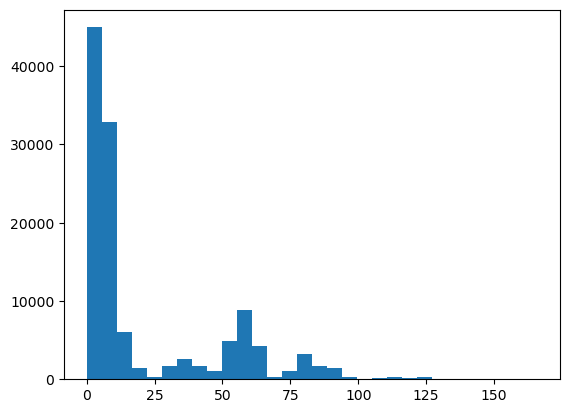

In [7]:
# Plot all the distances on a histogram. We see a bimodal distribution.
# Hopefully we can collapse all of the reads with very small distances.
plt.hist(distances[np.triu_indices(n_seqs)], bins=30);

<Axes: >

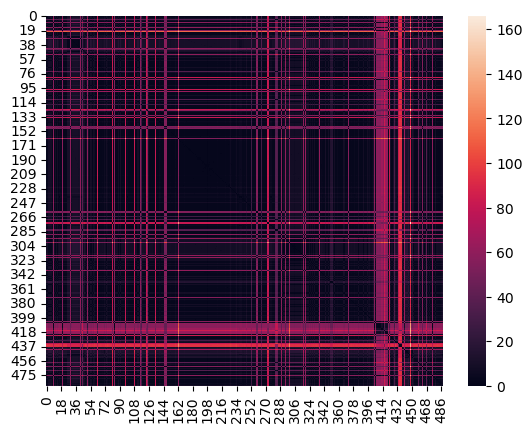

In [8]:
# The matrix plotted as a heatmap
sns.heatmap(distances)

In [9]:
# Set DBSCAN parameters
eps = 1.0  # tweak this based on your distance scale
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [10]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# The interpretation here is that 67 reads are in cluster -1 (meaning they are in a cluster by themselves),
# cluster 0 groups 262 reads together, etc.

Cluster -1: 67 items
Cluster 0: 262 items
Cluster 1: 70 items
Cluster 2: 6 items
Cluster 3: 13 items
Cluster 4: 8 items
Cluster 5: 17 items
Cluster 6: 2 items
Cluster 7: 4 items
Cluster 8: 2 items
Cluster 9: 7 items
Cluster 10: 9 items
Cluster 11: 3 items
Cluster 12: 2 items
Cluster 13: 3 items
Cluster 14: 2 items
Cluster 15: 2 items
Cluster 16: 2 items
Cluster 17: 4 items
Cluster 18: 4 items


<Axes: >

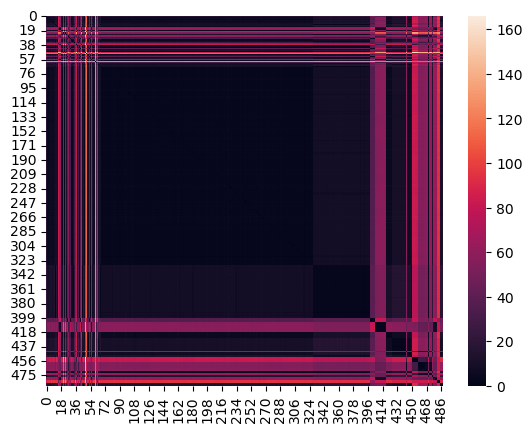

In [11]:
# Re-order the distance matrix based on the clusters and then plot.
sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]

sns.heatmap(reordered_distances)
# The giant black square in the middle represents one cluster.

<Axes: >

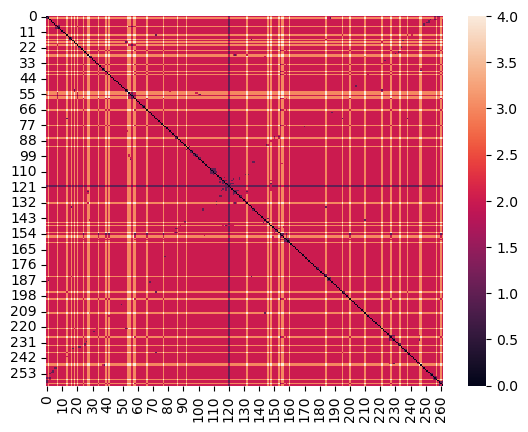

In [12]:
# Plot distances within the biggest cluster.
i = 0
indices_cluster_i = np.where(labels == i)[0]

cluster_i_seqs = unique_seqs[indices_cluster_i]
cluster_i_distances = distances[np.ix_(indices_cluster_i, indices_cluster_i)]

sns.heatmap(cluster_i_distances)

# Note that all of the sequences in this cluster have distance 4 or less from one another.

In [13]:
# Interestingly, the 120th sequence has distance 1 from almost every other sequence in this cluster,
# which may suggest that it is the "central" (or correct) sequence.
# This is clear in the heatmap above by the horizontal and vertical lines.
cluster_i_distances[120,:]

array([1., 2., 1., 1., 1., 1., 1., 2., 1., 1., 1., 1., 1., 2., 1., 1., 2.,
       1., 2., 1., 2., 1., 1., 1., 2., 1., 1., 2., 2., 1., 1., 1., 1., 1.,
       2., 1., 1., 1., 1., 2., 1., 2., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 2., 2., 2., 1., 2., 2., 1., 1., 1., 1., 1., 1., 1., 2., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 2., 1., 1., 1., 1., 1., 1., 1.,
       1., 2., 1., 1., 1., 1., 1., 2., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 2., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 2., 1., 2., 1., 1., 1., 1.,
       2., 1., 2., 2., 1., 1., 1., 2., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 2., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 2., 1., 1., 1., 1., 2., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 2., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       2., 1., 1., 1., 1.

In [14]:
# I did the clustering in a way that ignored the number of occurances of each sequence,
# but here are the counts of each sequence in our big cluster.
counts_cluster_i = seq_counts[indices_cluster_i]
counts_cluster_i

# We see that one sequence has the most reads, suggesting that it is the correct
# sequence (and every other read has small errors).

array([   2,    1,    4,    1,    2,    4,    1,    1,    1,    1,    1,
          2,    1,    1,    1,    2,    1,    2,    1,    1,    1,    2,
          1,    1,    1,    1,    1,    2,    1,    2,    2,    2,    2,
          1,    1,    1,    1,    2,    1,    1,    1,    2,    1,    1,
          1,    1,    1,    4,    1,    1,    2,    1,   23,    1,    1,
          1,   11,    1,    2,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    2,    1,    1,   41,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          2,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    2,    1,    3,    2,    1,    1,    1,    1,
          3,    1,    2,    4,    1,    1,    2,    1,    4,    1, 3098,
          1,    1,    7,    5,    3,    1,    1,    1,    1,    2,    2,
          1,    1,    1,    2,    1,    2,    1,    1,    1,    2,    1,
          1,    1,    1,    1,    1,    1,    1,   

In [15]:
# Compute the index corresponding to this large count.
argmax_indices = np.where(counts_cluster_i == np.max(counts_cluster_i))[0]
if len(argmax_indices) > 1:
    raise Exception('There are multiple sequences that achieve the max read count. Deal with this somehow')
else:
    index_high_count = argmax_indices[0]

print(f'Within the cluster, the index of the sequence that has the most reads is {index_high_count}. It contains {counts_cluster_i[index_high_count]} reads.')

# Hey look! We've seen 120 before; it was the sequence that was the most 'central' in the cluster
# when looking at the heatmap

Within the cluster, the index of the sequence that has the most reads is 120. It contains 3098 reads.


In [16]:
# Print this 'central' sequence for the cluster.
print(f'The sequence of this \'central\' cluster is {cluster_i_seqs[index_high_count]}')

# It does not make much sense for me to look at the quality score of this sequence since it corresponds to ~3,000 individual reads.

The sequence of this 'central' cluster is AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAGTCGAGAGCGCGCTCGTCGACTATGGAGTCGTCAGCAGTACTACTGACGATGGAGTCGACAGCAGTGTGTGAGTCTATGGAGTCGAGAGCATAGACATCGAGTATGGAGTCGACTACAGTCGCTACGACTATGGAGTCGACAGAGATATCATGCAGTATGGAGTCGACAGCAGTATCTGCTGTCATGGAGTCGACTGCACGACAGTCGACTATGGAGTCGCGAGCGCTATGAGCGACTATGGGCATGCAATTAAGTCTCAGCCACCGTTAACTGAACATGTCAAAACC


In [17]:
labels

array([ 0,  0,  1,  1,  2,  1,  1,  0,  3,  0,  0,  1,  0,  1,  0, -1,  4,
        0,  0,  3, -1,  0,  0,  0,  0, -1,  5,  5,  5,  6,  7,  7,  5,  5,
        5,  5,  5,  5,  5,  5,  5,  5,  6,  5, -1,  8,  5, -1,  0,  1, -1,
        1,  1,  0, -1,  1,  0,  0,  1, -1,  0,  0,  0, -1,  0,  0,  0,  0,
        1,  0,  0, -1, -1,  2,  1, -1,  0,  0,  0,  0,  0,  9,  0,  3,  0,
        0,  0,  0,  1,  0,  0,  1,  0,  0,  0,  0,  0, -1,  0, -1,  4,  0,
        0,  0,  0,  1,  0,  0,  9,  0,  2,  0,  1,  1,  0,  0, 10, -1,  0,
        0,  0,  0,  0,  9, 11,  1,  1,  0,  0,  0,  0, -1,  0,  0,  9,  0,
        0,  0,  0, -1, -1,  0,  0,  0,  0, 10, 10, -1, 10,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0, -1,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0

<Axes: >

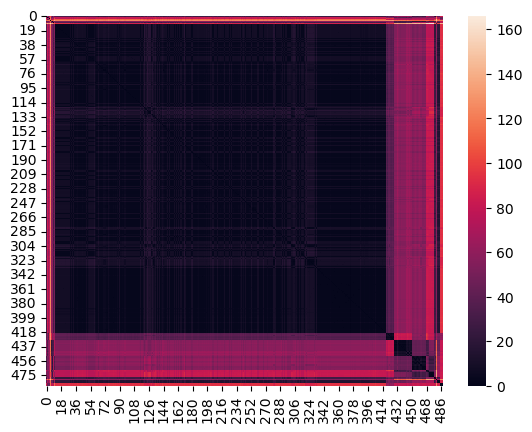

In [18]:
# Here is the same plot but with a larger clustering parameter value.
# This results in fewer clusters.

eps = 10
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')
labels = db.fit_predict(distances)

sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]
sns.heatmap(reordered_distances)

In [19]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# The interpretation here is that 67 reads are in cluster -1 (meaning they are in a cluster by themselves),
# cluster 0 groups 262 reads together, etc.

Cluster -1: 11 items
Cluster 0: 408 items
Cluster 1: 10 items
Cluster 2: 21 items
Cluster 3: 18 items
Cluster 4: 3 items
Cluster 5: 7 items
Cluster 6: 2 items
Cluster 7: 2 items
Cluster 8: 3 items
Cluster 9: 4 items


## Cluster using ALL sequences, including duplicates

This takes a lot longer to run...

In [20]:
n_seqs = len(sequences)
print(f'There are {n_seqs} sequences.')

There are 5341 sequences.


In [21]:
# Compute Levenshtein distance between every pair of reads.
# for 5341 reads, this takes about a minute to run.
distances = np.zeros((n_seqs, n_seqs))
for i in trange(n_seqs):
    for j in range(n_seqs):
        distances[i, j] = Levenshtein.distance(sequences[i], sequences[j])

100%|██████████████████████████████████████| 5341/5341 [00:46<00:00, 114.80it/s]


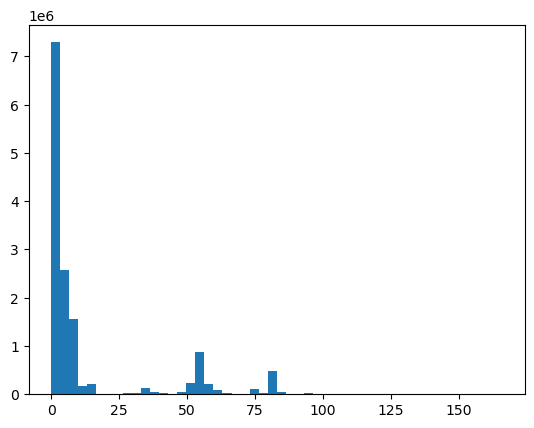

In [22]:
# Plot all the distances on a histogram.
plt.hist(distances[np.triu_indices(n_seqs)], bins=50);

# The left mode is a lot stronger here compared to when we removed duplicates - this makes sense to me.

<Axes: >

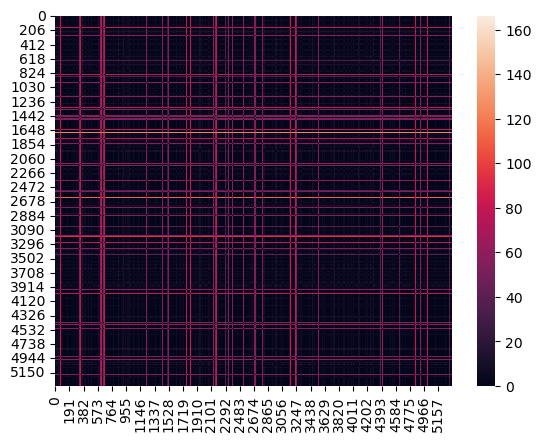

In [23]:
# The matrix plotted as a heatmap
sns.heatmap(distances)

In [24]:
# Cluster
eps = 1.0
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [25]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

# When we did not include duplicate sequences, we ended up with 18 clusters. Now, we have 33!

Cluster -1: 52 items
Cluster 0: 3651 items
Cluster 1: 6 items
Cluster 2: 857 items
Cluster 3: 195 items
Cluster 4: 113 items
Cluster 5: 2 items
Cluster 6: 194 items
Cluster 7: 33 items
Cluster 8: 53 items
Cluster 9: 41 items
Cluster 10: 3 items
Cluster 11: 13 items
Cluster 12: 16 items
Cluster 13: 8 items
Cluster 14: 21 items
Cluster 15: 3 items
Cluster 16: 11 items
Cluster 17: 9 items
Cluster 18: 6 items
Cluster 19: 3 items
Cluster 20: 3 items
Cluster 21: 9 items
Cluster 22: 5 items
Cluster 23: 8 items
Cluster 24: 2 items
Cluster 25: 3 items
Cluster 26: 4 items
Cluster 27: 3 items
Cluster 28: 2 items
Cluster 29: 2 items
Cluster 30: 4 items
Cluster 31: 2 items
Cluster 32: 2 items
Cluster 33: 2 items


<Axes: >

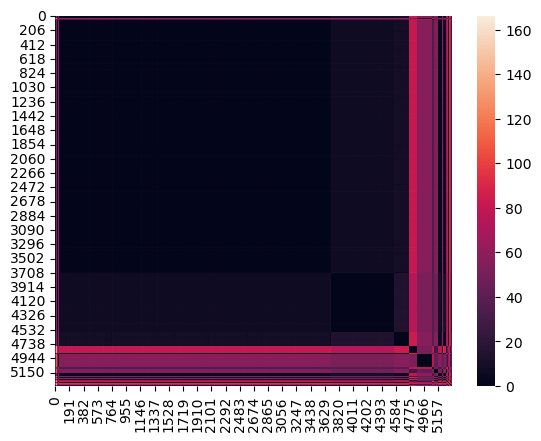

In [26]:
# Re-order the distance matrix based on the clusters and then plot.
sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]

sns.heatmap(reordered_distances)

# Don't be fooled - that big square in the middle is actually 3 clusters. You may have to squint to see it :)

In [27]:
# Still TBD whether it is better to cluster with or without duplicate sequences, or if it doesn't really matter.